# Estado de los datos: EDA del corpus actualizado

Este notebook describe los comentarios públicos reunidos para VOC antes del modelado de tópicos y sentimiento. Partirás del corpus fijado de **84.479 registros**, comprobarás su integridad y estudiarás composición, cobertura temporal y características del texto. Al final exportarás agregados y figuras que pueden utilizarse en la sección «Datos y preparación» del avance 6.

El antecedente `notebooks/Avance1.14Equipo.ipynb` describe la versión de 80.079 registros. Sus resultados se conservan como referencia histórica. Aquí analizarás el corpus actualizado completo, sin muestreo ni nuevas solicitudes a las plataformas. No entrenarás modelos, generarás embeddings ni llamarás a un LLM.

## 1. Preparando el entorno

Ejecuta **Restart Kernel and Run All Cells** con el entorno Python del Operador. El lector predeterminado utiliza el catálogo personal y ZenML. La alternativa explícita `parquet` permite verificar el mismo artefacto guardado sin el servidor ZenML. Ambas rutas comprueban el hash y la identidad del corpus.

Los resultados se escribirán únicamente en una carpeta nueva dentro de `data/reports/eda`. El notebook no exporta textos de reseñas ni identificadores individuales.

In [10]:
import hashlib
import importlib.metadata
import json
import os
import platform
import subprocess
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Localiza el checkout incluso si Jupyter abrió el notebook desde un enlace.
ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src/voc").is_dir() and (path / "pyproject.toml").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Abre el notebook desde el checkout de voc-main.")

from voc.datasets import get_dataset
from voc.datasets.shared.manifest import frame_hash
from voc.paths import data_root

# No aceptes por accidente un directorio de datos de otro checkout.
if "VOC_DATA_DIR" not in os.environ:
    os.environ["VOC_DATA_DIR"] = str(ROOT / "data")
DATA = data_root()
if DATA != (ROOT / "data").resolve():
    raise RuntimeError("VOC_DATA_DIR debe apuntar a data/ de este checkout.")

ARTIFACT_ID = "3862e53a-e9f4-47af-a644-35c2cc7c1945"
RAW_REVISION_ID = "9bcd1271-0427-40a9-a83c-9d2ff1008854"
EXPECTED_HASH = "40e8dea937da20d56b3a50bb432b424828ae12325c147f2f6b6a23b44339e027"
EXPECTED_ROWS = 84479
READER_MODE = "zenml"  # Cambia a "parquet" solo para lectura local sin ZenML.
EXPORT_RESULTS = True

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print("Checkout:", ROOT.name)
print("Lector:", READER_MODE)
print("Artefacto:", ARTIFACT_ID)

# Mantener la identidad visual de cada fuente en todas las figuras.
SOURCE_ORDER = ["google_play", "app_store", "x", "youtube"]
SOURCE_NAMES = {"google_play": "Google Play", "app_store": "App Store", "x": "X", "youtube": "YouTube"}
SOURCE_COLORS = {"google_play": "#276A96", "app_store": "#B16A26", "x": "#318276", "youtube": "#85629C"}


Checkout: workspace
Lector: zenml
Artefacto: 3862e53a-e9f4-47af-a644-35c2cc7c1945


## 2. Cargando una versión verificable

Carga el artefacto por su ID, sin utilizar `latest`. El catálogo personal resuelve un `artifact_id`, que es distinto del ID de una publicación compartida en S3.

La ruta Parquet corresponde a este artefacto concreto. Si seleccionas esa alternativa, el lector rechaza otro ID y las comprobaciones siguientes rechazan un contenido diferente.

In [11]:
class SavedParquetReader:
    """Lee el archivo inventariado, manteniendo la selección explícita."""

    def read(self, artifact_id):
        if artifact_id != ARTIFACT_ID:
            raise ValueError("El archivo configurado pertenece a otro artefacto.")
        path = DATA / (
            "zenml-artifacts/prepare/workable/"
            "19ae0e48-7081-4ce8-afc2-80f904916ab6/e36b7d52/df.parquet.gzip"
        )
        return pd.read_parquet(path)

if READER_MODE == "zenml":
    snapshot = get_dataset(ARTIFACT_ID, source="personal")
elif READER_MODE == "parquet":
    snapshot = get_dataset(ARTIFACT_ID, source="personal", reader=SavedParquetReader())
else:
    raise ValueError("READER_MODE debe ser zenml o parquet.")

# Comprueba identidad, contenido y hashes individuales antes de analizar.
frame = snapshot.data
assert snapshot.info["artifact_id"] == ARTIFACT_ID
assert snapshot.info["raw_revision_id"] == RAW_REVISION_ID
assert snapshot.info["schema_version"] == "workable-v1"
assert len(frame) == snapshot.info["row_count"] == EXPECTED_ROWS
assert frame_hash(frame) == snapshot.info["content_sha256"] == EXPECTED_HASH
assert frame["record_id"].map(lambda x: isinstance(x, str) and bool(x.strip())).all()
assert frame["record_id"].is_unique
assert frame["model_text"].map(lambda x: isinstance(x, str) and bool(x.strip())).all()
assert frame["model_text"].map(
    lambda text: hashlib.sha256(text.encode("utf-8")).hexdigest()
).eq(frame["text_hash"]).all()

identity = pd.DataFrame([
    {"campo": "artifact_id", "valor": ARTIFACT_ID},
    {"campo": "raw_revision_id", "valor": RAW_REVISION_ID},
    {"campo": "content_sha256", "valor": EXPECTED_HASH},
    {"campo": "registros", "valor": len(frame)},
    {"campo": "textos_distintos", "valor": frame["model_text"].nunique()},
])
display(identity)
print("Integridad verificada. Todas las filas participan en este EDA.")

,campo,valor
0,artifact_id,3862e53a-e9f4-47af-a644-35c2cc7c1945
1,raw_revision_id,9bcd1271-0427-40a9-a83c-9d2ff1008854
2,content_sha256,40e8dea937da20d56b3a50bb432b424828ae12325c147f...
3,registros,84479
4,textos_distintos,59550


Integridad verificada. Todas las filas participan en este EDA.


**Comprobación:** debes obtener 84.479 registros y 59.550 textos distintos. Los textos repetidos pertenecen a registros distintos. No se eliminan automáticamente ni se interpretan como errores de recolección.

## 3. Revisando la preparación aplicada

Compara el reporte de preparación con el catálogo. Las reglas describen qué podía hacer el proceso. Los recuentos muestran qué ocurrió en esta ejecución.

Se espera que entraran y salieran 84.479 registros, sin exclusiones. No se aplicaron filtros de idioma ni relevancia y no se antepuso el título al cuerpo. Esto no demuestra que todos los comentarios sean pertinentes para la aplicación.

In [12]:
report_path = DATA / (
    "zenml-artifacts/prepare/preparation_report/"
    "19ae0e48-7081-4ce8-afc2-80f904916ab6/4dcc70b0/data.json"
)
preparation = json.loads(report_path.read_text())
for field in ("raw_revision_id", "content_sha256", "schema_version", "row_count", "rules"):
    assert preparation[field] == snapshot.info[field], field
assert preparation["excluded_count"] == len(preparation["excluded"])
assert preparation["input_count"] == preparation["row_count"] + preparation["excluded_count"]

preparation_counts = pd.DataFrame([
    {"medida": key, "valor": preparation[key]}
    for key in ("input_count", "row_count", "excluded_count", "date_normalizations")
])
display(preparation_counts)
print(json.dumps(preparation["rules"], indent=2, ensure_ascii=False))

,medida,valor
0,input_count,84479
1,row_count,84479
2,excluded_count,0
3,date_normalizations,72814


{
  "columns": [
    "record_id",
    "platform",
    "app_id",
    "country",
    "text",
    "title",
    "model_text",
    "text_hash",
    "rating",
    "record_date",
    "date_basis",
    "date_precision",
    "date_timezone",
    "language",
    "language_basis",
    "relevance",
    "preferred_provider",
    "identity_basis"
  ],
  "blank_text": "exclude_and_report",
  "combine_title_body": false,
  "platforms": [
    "app_store",
    "google_play",
    "x",
    "youtube"
  ],
  "language_filter": null,
  "relevance_filter": null
}


Las normalizaciones de fechas recuperan timestamps existentes en la fuente cuando el registro conservaba solo el día aunque declaraba precisión de segundo. No son nuevas observaciones ni fechas inventadas. La preparación de `model_text` conserva el cuerpo con espacios exteriores recortados.

## 4. Describiendo las fuentes y sus fechas

Estudia conjuntamente volumen, intervalo observado y procedencia temporal. `record_date` puede representar publicación o actualización según la fuente. Una fecha interpretable no garantiza precisión de segundo ni conocimiento de la zona horaria.

La conversión a UTC permite agrupar, pero no convierte en UTC conocido las fechas de origen desconocido. La medianoche añadida a una fecha de día es una representación computacional.

In [13]:
# Las columnas analíticas se crean aparte, sin cambiar el dataset original.
dates = pd.to_datetime(frame["record_date"], errors="coerce", format="mixed", utc=True)
ratings = pd.to_numeric(frame["rating"], errors="coerce")
texts = frame["model_text"]
lengths = texts.str.len()
platforms = sorted(frame["platform"].unique())

coverage = (
    frame.assign(parsed_date=dates).groupby("platform")
    .agg(registros=("record_id", "size"), fechas_validas=("parsed_date", "count"),
         primera_fecha=("parsed_date", "min"), ultima_fecha=("parsed_date", "max"))
)
coverage["porcentaje_corpus"] = coverage["registros"] / len(frame) * 100
coverage["sin_fecha_interpretable"] = coverage["registros"] - coverage["fechas_validas"]
coverage["fechas_presentes_no_interpretables"] = (
    frame.assign(invalid=frame["record_date"].notna() & dates.isna())
    .groupby("platform")["invalid"].sum()
)
provenance = (
    frame.groupby(["platform", "date_basis", "date_precision", "date_timezone"], dropna=False)
    .size().rename("registros").reset_index()
)
assert coverage["registros"].sum() == len(frame)
display(coverage)
display(provenance)

,registros,fechas_validas,primera_fecha,ultima_fecha,porcentaje_corpus,sin_fecha_interpretable,fechas_presentes_no_interpretables
platform,,,,,,,
app_store,5623,5623,2025-09-01 00:00:00+00:00,2026-10-24 14:53:14+00:00,6.656092,0,0
google_play,70975,70975,2025-09-13 01:53:42+00:00,2026-10-24 23:08:29+00:00,84.014962,0,0
x,6553,6553,2025-09-01 13:34:27+00:00,2026-09-14 23:54:01+00:00,7.756957,0,0
youtube,1328,1328,2025-09-01 04:33:28+00:00,2026-09-16 20:18:39+00:00,1.571988,0,0


,platform,date_basis,date_precision,date_timezone,registros
0,app_store,provider_published_at,day,unknown,5151
1,app_store,source_updated_at,second,UTC,472
2,google_play,source_updated_at,second,UTC,70975
3,x,earliest_observed_edit_family_creation,second,UTC,6553
4,youtube,published_at,second,UTC,1328


### Observando la distribución mensual

Cada barra cuenta registros según `record_date`. Los paneles conservan el mismo eje temporal para mostrar la diferencia entre fuentes. Se marcan los meses sin registros observados, sin afirmar que su actividad real haya sido nula. Los extremos del intervalo pueden ser meses parciales.

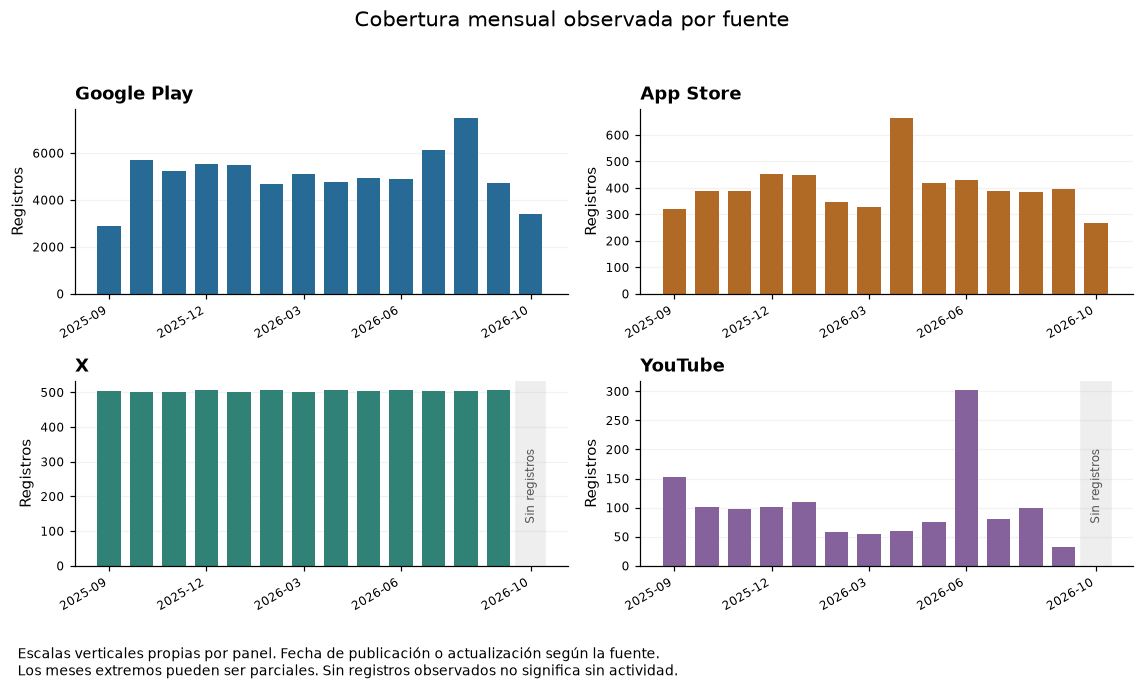

platform,google_play,app_store,x,youtube
mes_record_date,,,,
2025-09,2893,319,503,153
2025-10,5700,390,501,101
2025-11,5237,389,500,98
2025-12,5532,453,508,101
2026-01,5493,448,502,110
2026-02,4659,345,507,58
2026-03,5112,329,501,55
2026-04,4777,666,506,60
2026-05,4946,418,505,75


In [14]:
month = dates.dt.strftime("%Y-%m")
monthly_observed = pd.crosstab(month, frame["platform"]).reindex(columns=SOURCE_ORDER, fill_value=0)
all_months = pd.period_range(month.dropna().min(), month.dropna().max(), freq="M").astype(str)
monthly = monthly_observed.reindex(all_months, fill_value=0)
monthly.index.name = "mes_record_date"
assert int(monthly.to_numpy().sum()) == int(dates.notna().sum())

fig_monthly, axes = plt.subplots(2, 2, figsize=(10.5, 6.4), sharex=True)
positions = np.arange(len(monthly))
ticks = sorted(set(range(0, len(monthly), 3)) | {len(monthly) - 1})
if len(ticks) > 1 and ticks[-1] - ticks[-2] == 1:
    ticks.pop(-2)
for ax, source in zip(axes.flat, SOURCE_ORDER, strict=True):
    counts = monthly[source].to_numpy()
    observed = counts > 0
    ax.bar(positions[observed], counts[observed], color=SOURCE_COLORS[source], width=0.72)
    for index in positions[~observed]:
        ax.axvspan(index - 0.45, index + 0.45, color="#eeeeee", zorder=0)
        ax.text(index, max(counts.max(), 1) * 0.45, "Sin registros",
                rotation=90, ha="center", va="center", fontsize=8, color="#555555")
    ax.set_title(SOURCE_NAMES[source], loc="left", fontweight="bold")
    ax.set_ylabel("Registros")
    ax.set_ylim(bottom=0)
    ax.set_xticks(ticks, [monthly.index[i] for i in ticks], rotation=30, ha="right")
    ax.tick_params(labelbottom=True, labelsize=8)
    ax.grid(axis="y", alpha=0.16)
    ax.set_axisbelow(True)
fig_monthly.suptitle("Cobertura mensual observada por fuente", fontsize=14)
fig_monthly.tight_layout(rect=(0, 0.10, 1, 0.95))
fig_monthly.text(0.02, 0.035,
    "Escalas verticales propias por panel. Fecha de publicación o actualización según la fuente.\n"
    "Los meses extremos pueden ser parciales. Sin registros observados no significa sin actividad.", fontsize=9)
plt.show()
display(monthly)

**Comprobación:** las fuentes deben sumar el corpus completo. Contrasta el último mes de las tiendas con X y YouTube. No compares sus totales como si sus periodos y mecanismos de recolección fueran iguales. Los paneles usan escalas verticales propias para permitir leer las fuentes pequeñas.

## 5. Identificando faltantes y repetición de textos

Construye una tabla por variable y otra por plataforma. Distingue valores nulos de campos cuyo estado está registrado como desconocido. Por ejemplo, `unreviewed` es una categoría de relevancia y no un valor nulo.

La repetición se mide sobre el texto exacto preparado, sin convertirlo a minúsculas ni eliminar signos. Esto describe coincidencias textuales, no similitud semántica.

In [15]:
quality = pd.DataFrame({
    "variable": frame.columns,
    "tipo": frame.dtypes.astype(str).to_numpy(),
    "nulos": frame.isna().sum().to_numpy(),
    "porcentaje_nulos": (frame.isna().mean() * 100).to_numpy(),
    "valores_distintos_no_nulos": frame.nunique(dropna=True).to_numpy(),
})
missing_by_source = (
    frame[["platform", "title", "language", "rating", "record_date"]]
    .groupby("platform").agg(lambda column: int(column.isna().sum()))
)
# keep=False cuenta todas las filas que participan en un grupo repetido.
repeated_global = texts.duplicated(keep=False)
repeated_within = frame.duplicated(subset=["platform", "model_text"], keep=False)
text_repetition = (
    frame.assign(repetido_en_corpus=repeated_global, repetido_en_fuente=repeated_within)
    .groupby("platform").agg(
        registros=("record_id", "size"), textos_distintos=("model_text", "nunique"),
        filas_en_grupos_repetidos_globales=("repetido_en_corpus", "sum"),
        filas_en_grupos_repetidos_en_fuente=("repetido_en_fuente", "sum"),
    )
)
text_repetition["porcentaje_repetido_en_fuente"] = (
    text_repetition["filas_en_grupos_repetidos_en_fuente"] / text_repetition["registros"] * 100
)
label_states = (
    frame.groupby(["platform", "relevance"], dropna=False)
    .size().rename("registros").reset_index()
)
display(quality)
display(missing_by_source)
display(text_repetition)
display(label_states)
print("Identificadores duplicados:", int(frame["record_id"].duplicated().sum()))
print("Textos distintos globales:", texts.nunique())

,variable,tipo,nulos,porcentaje_nulos,valores_distintos_no_nulos
0,record_id,string,0,0.000000,84479
1,platform,string,0,0.000000,4
2,app_id,string,7881,9.328946,2
3,country,string,7881,9.328946,1
4,text,string,0,0.000000,59550
5,title,string,78856,93.343908,3371
6,model_text,string,0,0.000000,59550
7,text_hash,string,0,0.000000,59550
8,rating,Int64,7881,9.328946,5
9,record_date,string,0,0.000000,79567


,title,language,rating,record_date
platform,,,,
app_store,0,479,0,0
google_play,70975,70975,0,0
x,6553,0,6553,0
youtube,1328,1328,1328,0


,registros,textos_distintos,filas_en_grupos_repetidos_globales,filas_en_grupos_repetidos_en_fuente,porcentaje_repetido_en_fuente
platform,,,,,
app_store,5623,5394,437,329,5.850969
google_play,70975,46471,26580,26519,37.363861
x,6553,6534,34,34,0.518846
youtube,1328,1316,27,20,1.506024


,platform,relevance,registros
0,app_store,app_target_match,5623
1,google_play,app_target_match,70975
2,x,unreviewed,6553
3,youtube,human_irrelevant,47
4,youtube,human_relevant,50
5,youtube,human_uncertain,8
6,youtube,unreviewed,1223


Identificadores duplicados: 0
Textos distintos globales: 59550


### Resumiendo la composición y los metadatos

La composición permite reconocer qué fuente pesa más en los agregados. La disponibilidad se calcula dentro de cada plataforma: un porcentaje alto no garantiza exactitud ni pertinencia. La fecha interpretable tampoco demuestra que su hora o zona sean conocidas.

El panel izquierdo muestra volumen y participación. El derecho distingue información disponible de un campo que no corresponde a la fuente. Las estrellas se marcan como «No aplica» para X y YouTube. Un idioma no informado no se interpreta como un idioma diferente.

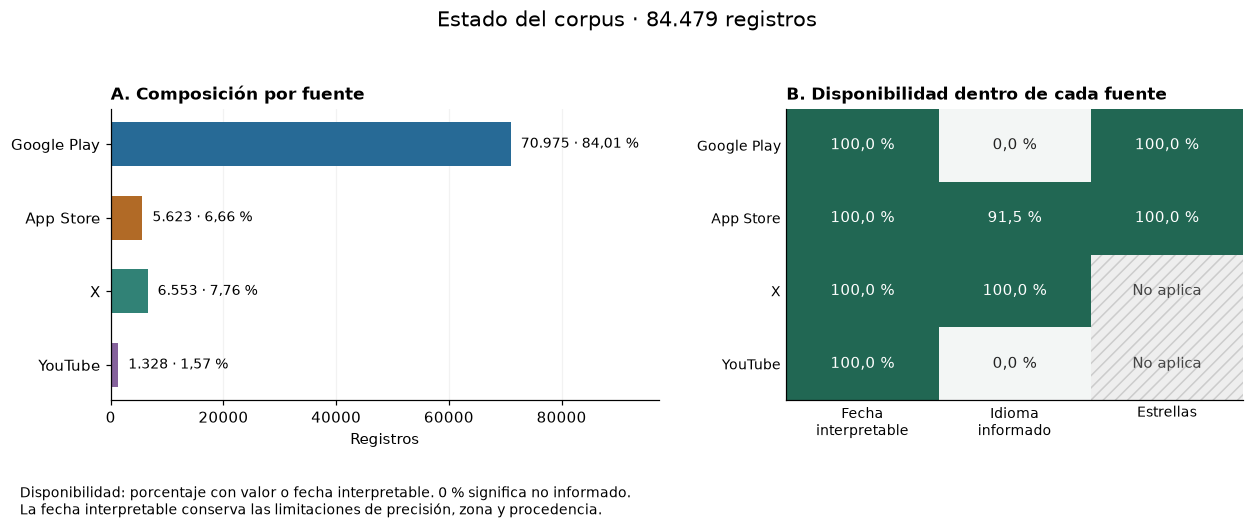

,Fecha interpretable,Idioma informado,Estrellas
platform,,,
google_play,100.0,0.000000,100.0
app_store,100.0,91.481416,100.0
x,100.0,100.000000,NaN
youtube,100.0,0.000000,NaN


In [16]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle

source_counts = coverage["registros"].reindex(SOURCE_ORDER)
metadata_coverage = pd.DataFrame(index=SOURCE_ORDER)
metadata_coverage["Fecha interpretable"] = (
    dates.notna().groupby(frame["platform"]).mean().reindex(SOURCE_ORDER) * 100
)
metadata_coverage["Idioma informado"] = (
    frame["language"].notna().groupby(frame["platform"]).mean().reindex(SOURCE_ORDER) * 100
)
metadata_coverage["Estrellas"] = (
    ratings.notna().groupby(frame["platform"]).mean().reindex(SOURCE_ORDER) * 100
)
metadata_coverage.loc[["x", "youtube"], "Estrellas"] = np.nan
metadata_coverage.index.name = "platform"
assert source_counts.sum() == len(frame)

fig_state, (ax_counts, ax_meta) = plt.subplots(
    1, 2, figsize=(11.5, 4.8), gridspec_kw={"width_ratios": [1.2, 1]},
)
y = np.arange(len(SOURCE_ORDER))
ax_counts.barh(y, source_counts, color=[SOURCE_COLORS[s] for s in SOURCE_ORDER], height=0.6)
ax_counts.set_yticks(y, [SOURCE_NAMES[s] for s in SOURCE_ORDER])
ax_counts.invert_yaxis()
ax_counts.set_xlim(0, source_counts.max() * 1.37)
ax_counts.set_xlabel("Registros")
ax_counts.set_title("A. Composición por fuente", loc="left", fontweight="bold", fontsize=11)
ax_counts.ticklabel_format(style="plain", axis="x")
ax_counts.grid(axis="x", alpha=0.16)
ax_counts.set_axisbelow(True)
for i, count in enumerate(source_counts):
    label = f"{count:,} · {100 * count / len(frame):.2f} %".replace(",", "_").replace(".", ",").replace("_", ".")
    ax_counts.text(count + source_counts.max() * 0.025, i, label, va="center", fontsize=9)

palette = ListedColormap(["#f3f6f5", "#cee1dc", "#9bc4b9", "#609e8e", "#216753"])
palette.set_bad("#eeeeee")
ax_meta.imshow(np.ma.masked_invalid(metadata_coverage.to_numpy()), cmap=palette,
               vmin=0, vmax=100, aspect="auto")
ax_meta.set_xticks(range(3), ["Fecha\ninterpretable", "Idioma\ninformado", "Estrellas"])
ax_meta.set_yticks(y, [SOURCE_NAMES[s] for s in SOURCE_ORDER])
ax_meta.set_title("B. Disponibilidad dentro de cada fuente", loc="left", fontweight="bold", fontsize=11)
ax_meta.tick_params(length=0, labelsize=9)
for row in range(4):
    for col in range(3):
        value = metadata_coverage.iloc[row, col]
        if pd.isna(value):
            ax_meta.add_patch(Rectangle((col - 0.5, row - 0.5), 1, 1, fill=False,
                                       hatch="///", edgecolor="#cccccc", linewidth=0))
            label, color = "No aplica", "#444444"
        else:
            label, color = f"{value:.1f} %".replace(".", ","), "white" if value >= 60 else "#222222"
        ax_meta.text(col, row, label, ha="center", va="center", color=color, fontsize=10)
fig_state.suptitle(f"Estado del corpus · {len(frame):,} registros".replace(",", "."), fontsize=14)
fig_state.tight_layout(rect=(0, 0.12, 1, 0.94), w_pad=2.5)
fig_state.text(0.02, 0.025,
    "Disponibilidad: porcentaje con valor o fecha interpretable. 0 % significa no informado.\n"
    "La fecha interpretable conserva las limitaciones de precisión, zona y procedencia.", fontsize=9)
plt.show()
display(metadata_coverage)

## 6. Explorando longitudes y formas de expresión

Mide caracteres del texto preparado, no tokens del encoder. Los límites de tokenización y el truncamiento se estudiarán al completar embeddings. Una reseña larga no es necesariamente un error.

Las reglas de signos, negaciones o emojis son indicadores exploratorios aproximados. No constituyen etiquetas de sentimiento.

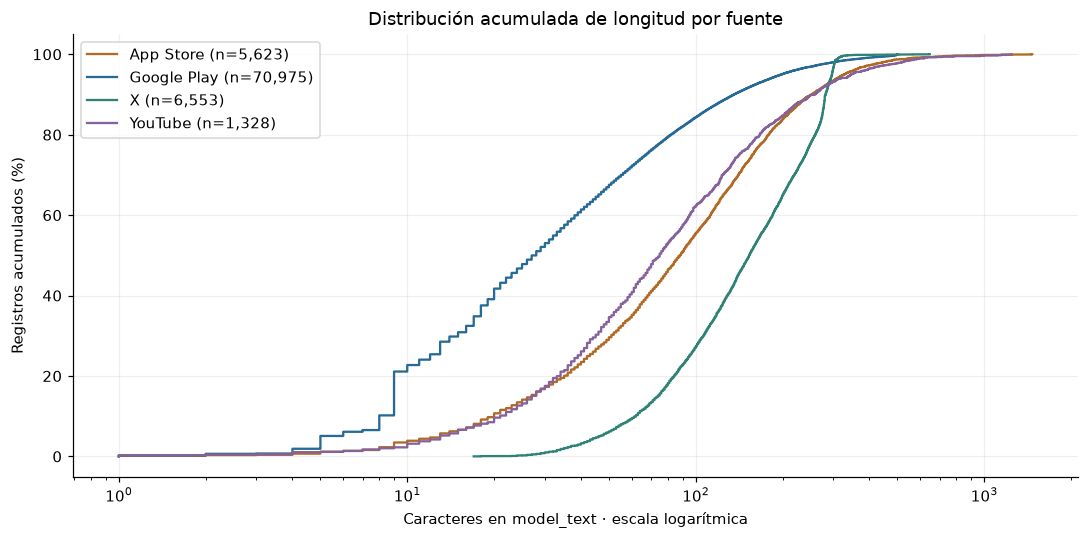

,registros,media,mediana,minimo,maximo,p95
platform,,,,,,
app_store,5623,119.819669,88.0,1,1468,326.90
google_play,70975,55.130652,28.0,1,500,199.00
x,6553,165.444834,153.0,17,648,297.00
youtube,1328,115.369729,75.0,1,1242,345.65


,q1_caracteres,q3_caracteres,umbral_superior_IQR,filas_sobre_umbral,porcentaje_sobre_umbral
0,14.0,90.0,204.0,6606,7.819695


,patron,registros,porcentaje_corpus
0,negaciones,24945,29.528048
1,urls,1055,1.248831
2,signos_repetidos,1867,2.210017
3,mayusculas,3636,4.304028
4,emojis_aproximados,4596,5.440405


In [17]:
length_summary = (
    frame.assign(caracteres=lengths).groupby("platform")["caracteres"]
    .agg(registros="size", media="mean", mediana="median", minimo="min", maximo="max",
         p95=lambda s: s.quantile(0.95))
)
q1, q3 = lengths.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
length_diagnostics = pd.DataFrame([{
    "q1_caracteres": q1, "q3_caracteres": q3, "umbral_superior_IQR": upper,
    "filas_sobre_umbral": int(lengths.gt(upper).sum()),
    "porcentaje_sobre_umbral": float(lengths.gt(upper).mean() * 100),
}])
fig_lengths, ax = plt.subplots(figsize=(10, 5))
for source in platforms:
    values = np.sort(lengths[frame["platform"].eq(source)].to_numpy(dtype=float))
    ax.step(values, np.arange(1, len(values) + 1) / len(values) * 100,
            where="post", color=SOURCE_COLORS[source], label=f"{SOURCE_NAMES[source]} (n={len(values):,})")
ax.set_xscale("log")
ax.set(xlabel="Caracteres en model_text · escala logarítmica",
       ylabel="Registros acumulados (%)", title="Distribución acumulada de longitud por fuente")
ax.legend()
ax.grid(alpha=0.2)
fig_lengths.tight_layout()
plt.show()

pattern_rules = {
    "negaciones": r"(?i)\b(?:no|nunca|jamás|tampoco|sin|ni)\b",
    "urls": r"https?://\S+|www\.\S+",
    "signos_repetidos": r"[!?¡¿]{2,}",
    "mayusculas": r"\b[A-ZÁÉÍÓÚÜÑ]{2,}\b",
    "emojis_aproximados": r"[\U0001F300-\U0001FAFF\u2600-\u27BF]",
}
patterns = pd.DataFrame([
    {"patron": name, "registros": int(texts.str.contains(rule, regex=True, na=False).sum()),
     "porcentaje_corpus": float(texts.str.contains(rule, regex=True, na=False).mean() * 100)}
    for name, rule in pattern_rules.items()
])
display(length_summary)
display(length_diagnostics)
display(patterns)

En la curva acumulada puedes leer qué porcentaje de cada fuente queda por debajo de una longitud. El eje logarítmico permite mostrar los textos extensos sin eliminarlos. El criterio IQR solo señala casos para inspección, no aplica exclusiones.

## 7. Separando valoraciones y etiquetas

Resume las estrellas solo entre registros que las tienen. No asignes estrellas a X o YouTube ni traduzcas automáticamente 1–2 estrellas a una etiqueta negativa. Las valoraciones son una variable observada, mientras las etiquetas usadas para entrenar o evaluar un modelo requieren un protocolo y una procedencia propios.

In [18]:
assert ratings.dropna().isin([1, 2, 3, 4, 5]).all()
rating_counts = pd.crosstab(frame["platform"], ratings).reindex(
    index=platforms, columns=[1, 2, 3, 4, 5], fill_value=0
)
rating_counts.columns.name = "estrellas"
rated_count = rating_counts.sum(axis=1)
rating_percent = rating_counts.div(rated_count.replace(0, np.nan), axis=0) * 100
rating_coverage = pd.DataFrame({
    "registros": coverage["registros"], "con_estrellas": rated_count,
    "sin_estrellas": coverage["registros"] - rated_count,
})
assert int(rated_count.sum()) == int(ratings.notna().sum())
display(rating_coverage)
display(rating_counts)
display(rating_percent)
print("NaN en porcentajes significa que la fuente no tiene valoraciones observadas.")

,registros,con_estrellas,sin_estrellas
platform,,,
app_store,5623,5623,0
google_play,70975,70975,0
x,6553,0,6553
youtube,1328,0,1328


estrellas,1,2,3,4,5
platform,,,,,
app_store,2515,526,641,370,1571
google_play,10873,3043,4307,7316,45436
x,0,0,0,0,0
youtube,0,0,0,0,0


estrellas,1,2,3,4,5
platform,,,,,
app_store,44.727014,9.354437,11.399609,6.580117,27.938823
google_play,15.319479,4.287425,6.068334,10.307855,64.016907
x,NaN,NaN,NaN,NaN,NaN
youtube,NaN,NaN,NaN,NaN,NaN


NaN en porcentajes significa que la fuente no tiene valoraciones observadas.


## 8. Interpretando los resultados para el avance 6

Redacta a partir de las salidas de esta ejecución. Para el cuerpo del artículo selecciona cobertura, calidad, distribución mensual y longitudes. Usa las otras tablas como respaldo.

- Explica la composición por fuente sin equipararla con la población total de clientes.
- Distingue faltantes estructurales, como estrellas en redes sociales, de datos cuya procedencia debe revisarse.
- Señala que la fecha de actualización no representa necesariamente el momento de creación del comentario.
- No interpretes meses sin observaciones como ausencia de problemas. Tampoco supongas cobertura continua entre la primera y la última fecha.
- Describe la preparación efectivamente aplicada. Los filtros de relevancia, las particiones y las etiquetas de evaluación requieren evidencia posterior.
- Los embeddings no se calculan aquí. Este EDA tampoco demuestra que su caché sea compatible con el entorno productor.

### Reto: relacionando calidad y metodología

Elige dos hallazgos de las tablas y explica qué decisión metodológica podrían orientar. Por ejemplo, compara la longitud entre fuentes y plantea cómo comprobarías el truncamiento del encoder. Separa lo observado de lo que aún requiere un experimento.

### Puntos clave

- **Identidad:** todas las salidas corresponden a una versión concreta del corpus.
- **Cobertura:** los periodos y la procedencia de las fechas cambian entre fuentes.
- **Repetición:** textos iguales no implican registros duplicados.
- **Representación:** caracteres, tokens y embeddings son medidas diferentes.
- **Evidencia:** las tablas y figuras se regeneran desde los datos, con un manifiesto de ejecución.

Estas salidas respaldan la sección de datos y preparación. La libreta de embeddings explica la representación numérica y conserva el resultado de su producción verificada, mientras la evaluación de los modelos se desarrolla en metodología.

## 9. Exportando resultados para el reporte

Exportamos las tablas y figuras de esta libreta para crear el reporte. Se guardan en `data/reports/eda/<artifact_id>/<ejecución>/`, con imágenes PNG, figuras PDF y un manifiesto de procedencia.

In [19]:
tables = {
    "identidad": identity, "preparacion": preparation_counts,
    "cobertura": coverage.reset_index(), "procedencia_fechas": provenance,
    "distribucion_mensual": monthly.reset_index(), "calidad": quality,
    "faltantes_por_fuente": missing_by_source.reset_index(),
    "repeticion_textos": text_repetition.reset_index(), "estados_relevancia": label_states,
    "longitudes": length_summary.reset_index(), "diagnostico_longitudes": length_diagnostics,
    "patrones_textuales": patterns, "cobertura_estrellas": rating_coverage.reset_index(),
    "conteos_estrellas": rating_counts.reset_index(),
    "porcentajes_estrellas": rating_percent.reset_index(),
    "disponibilidad_metadatos": metadata_coverage.reset_index(),
}
# Comprueba que los cálculos no modificaron el corpus original.
assert frame_hash(frame) == EXPECTED_HASH

if EXPORT_RESULTS:
    execution = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    destination = DATA / "reports/eda" / ARTIFACT_ID / execution
    destination.mkdir(parents=True, exist_ok=False)
    for name, table in tables.items():
        table.to_csv(destination / f"{name}.csv", index=False)
    figures = {"estado_del_corpus": fig_state, "cobertura_mensual": fig_monthly, "longitudes": fig_lengths}
    for name, figure in figures.items():
        figure.savefig(destination / f"{name}.png", dpi=220, bbox_inches="tight", facecolor="white")
        figure.savefig(destination / f"{name}.pdf", bbox_inches="tight", facecolor="white")

    def git_output(*args):
        result = subprocess.run(["git", "-C", str(ROOT), *args], capture_output=True, text=True)
        return result.stdout.strip() if result.returncode == 0 else None

    git_status = git_output("status", "--porcelain")
    manifest = {
        "execution_utc": execution, "artifact_id": ARTIFACT_ID,
        "raw_revision_id": RAW_REVISION_ID, "content_sha256": EXPECTED_HASH,
        "rows": len(frame), "unique_model_texts": int(texts.nunique()),
        "reader": READER_MODE, "sample": None, "preparation_rules": preparation["rules"],
        "commit": git_output("rev-parse", "HEAD"),
        "working_tree_dirty": None if git_status is None else bool(git_status),
        "python": platform.python_version(),
        "versions": {name: importlib.metadata.version(name)
                     for name in ("pandas", "numpy", "pyarrow", "matplotlib")},
        "date_interpretation": "UTC para resumen. Las fechas con zona desconocida conservan esa limitación.",
        "files_sha256": {path.name: hashlib.sha256(path.read_bytes()).hexdigest()
                         for path in sorted(destination.iterdir()) if path.is_file()},
    }
    notebook_path = ROOT / "reports/eda/estado-de-los-datos.ipynb"
    manifest["notebook_file_sha256"] = hashlib.sha256(notebook_path.read_bytes()).hexdigest()
    (destination / "manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False))
    print("Resultados guardados en:", destination.relative_to(ROOT))
else:
    print("Exportación deshabilitada. Las tablas y figuras permanecen en memoria.")

Resultados guardados en: data/reports/eda/3862e53a-e9f4-47af-a644-35c2cc7c1945/20261103T010110556951Z
